In [7]:
import numpy as np
data = np.loadtxt("spur 1_40hz_High_1.txt")

print(data.shape)
print(data[:5])

(266656, 3)
[[ 0.010834   -0.004425    0.043945  ]
 [ 0.010681   -0.0027466   0.032959  ]
 [ 0.010986   -0.0012207   0.041504  ]
 [ 0.013123    0.00045776  0.0354    ]
 [ 0.016174    0.0016785   0.0354    ]]


In [8]:
fs = 66666.67
t = np.arange(len(data)) / fs
print("N:", len(data))
print("Duration:", len(data) / fs)

N: 266656
Duration: 3.99983980000801


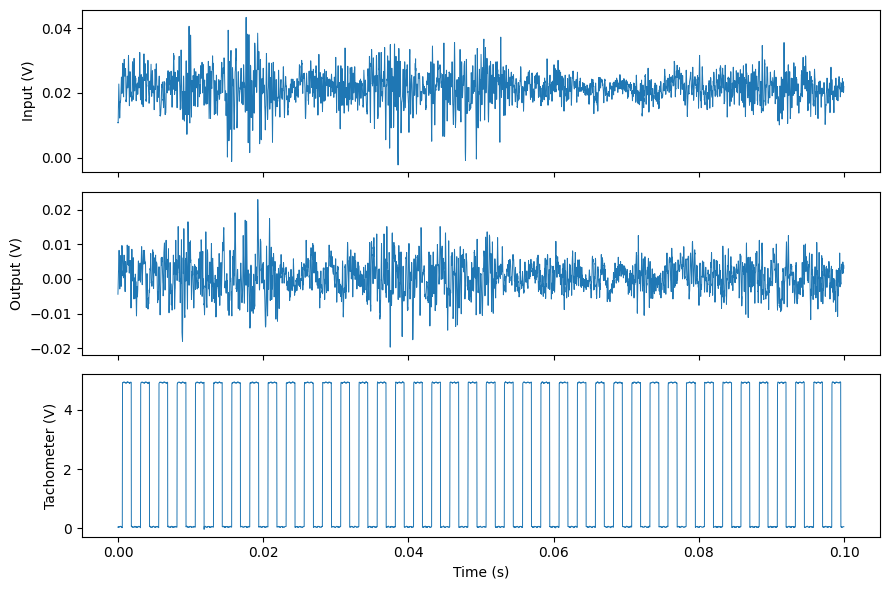

In [9]:
import matplotlib.pyplot as plt

n = int(0.1 * fs)
fig, axes = plt.subplots(3, 1, sharex=True, figsize=(9, 6))
names = ["Input (V)", "Output (V)", "Tachometer (V)"]

for i in range(3):
    axes[i].plot(t[:n], data[:n, i], linewidth=0.7)
    axes[i].set_ylabel(names[i])
axes[-1].set_xlabel("Time (s)")
plt.tight_layout()
plt.show()


In [10]:
x = data[:, 0]
mean = np.mean(x)
rms = np.sqrt(np.mean(x**2))
ac_rms = np.sqrt(np.mean((x - mean)**2))

print("Mean:", mean)
print("RMS:", rms)
print("AC RMS:", ac_rms)

Mean: 0.021573298923931963
RMS: 0.022083642324936894
AC RMS: 0.004720172864887529


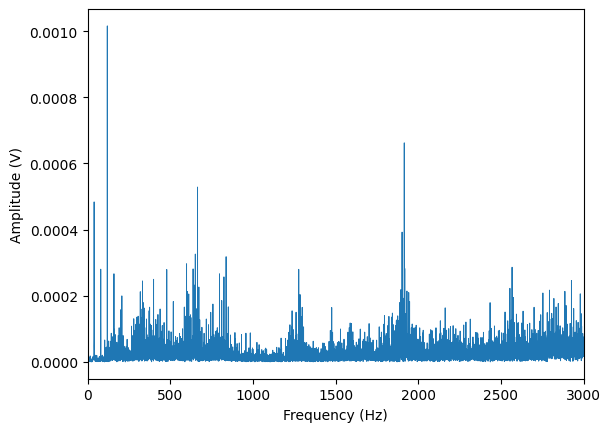

In [11]:
x = x - np.mean(x)
X = np.fft.rfft(x)
f = np.fft.rfftfreq(len(x), 1/fs)
A = 2*np.abs(X) / len(x)

plt.plot(f, A, linewidth=0.7)
plt.xlim(0, 3000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (V)")
plt.show()

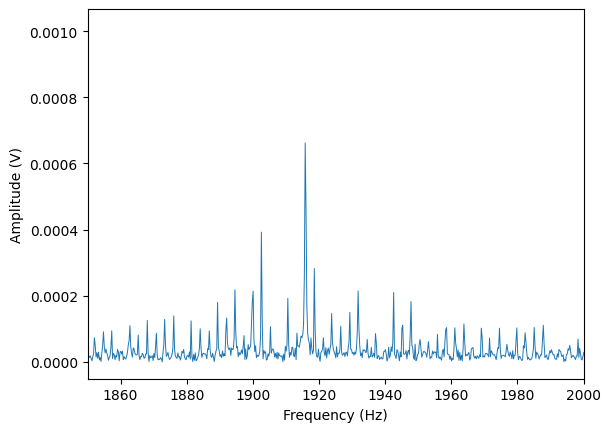

In [12]:
plt.plot(f, A, linewidth=0.7)
plt.xlim(1850, 2000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (V)")
plt.show()

In [13]:
band = (f >= 1910) & (f <= 1920)
fc = f[band][np.argmax(A[band])]
print("Peak frequency:", fc)


Peak frequency: 1915.8267288566544


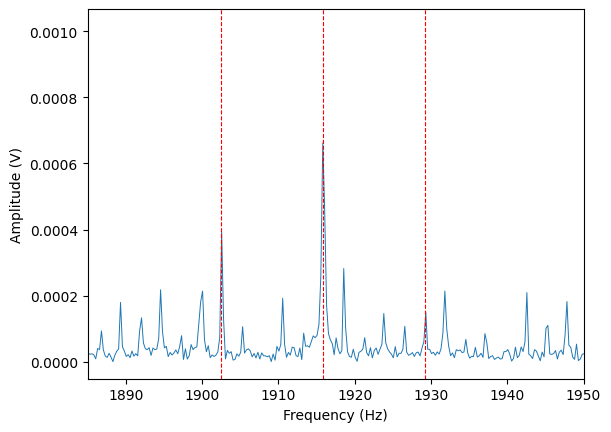

In [14]:
fm = 40 / 3

plt.plot(f, A, linewidth=0.7)

for frequency in [fc-fm, fc, fc+fm]:
    plt.axvline(frequency, color="red", linestyle="--", linewidth=0.8)

plt.xlim(1885, 1950)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (V)")
plt.show()

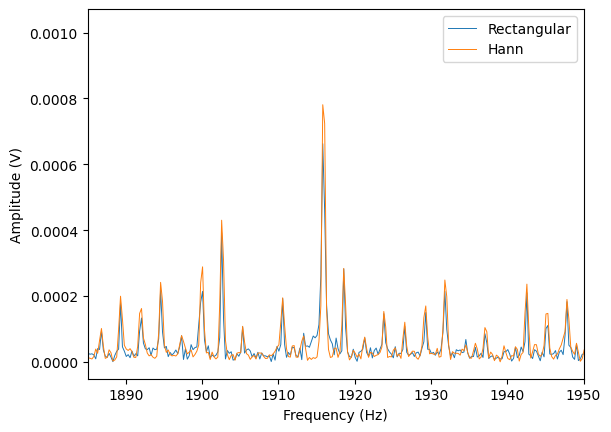

In [15]:
w = np.hanning(len(x))

Xw = np.fft.rfft(x * w)
Aw = 2 * np.abs(Xw) / np.sum(w)

plt.plot(f, A, label="Rectangular", linewidth=0.7)
plt.plot(f, Aw, label="Hann", linewidth=0.7)

plt.xlim(1885, 1950)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Amplitude (V)")
plt.legend()
plt.show()

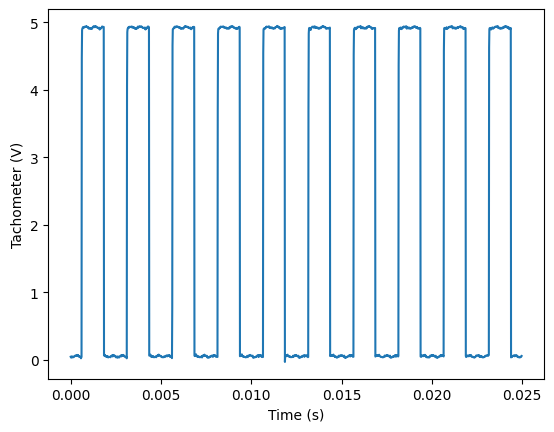

Detected pulses: 1597
RPM: 2395.2097005988026
Input frequency (Hz): 39.92016167664671
Pulse intervals (ms): [2.48999988 2.50499987 2.51999987]


In [16]:
p = data[:, 2]

n = int(0.025 * fs)
plt.plot(np.arange(n) / fs, p[:n])
plt.xlabel("Time (s)")
plt.ylabel("Tachometer (V)")
plt.show()

low, high = np.percentile(p, [5, 95])
level = (low + high) / 2

edges = np.where((p[:-1] < level) & (p[1:] >= level))[0] + 1
print("Detected pulses:", len(edges))


periods = (edges[10:] - edges[:-10]) / fs
rpm = 60 / np.median(periods)
print("RPM:", rpm)
print("Input frequency (Hz):", rpm / 60)

dt = np.diff(edges) / fs
print("Pulse intervals (ms):", np.percentile(dt, [5, 50, 95]) * 1000)

In [17]:
from scipy.signal import periodogram

In [18]:
for case in [1, 3]:
    data = np.loadtxt(f"spur {case}_40hz_High_1.txt")

    p = data[:, 2]
    low, high = np.percentile(p, [5, 95])
    level = (low + high) / 2
    edges = np.where((p[:-1] < level) & (p[1:] >= level))[0] + 1

    fin = fs / np.median(edges[10:] - edges[:-10])

    x = data[:, 0] - np.mean(data[:, 0])
    f, psd = periodogram(x, fs, window="hann", scaling="density")
    df = f[1] - f[0]

    fc = 48 * fin
    fm = fin / 3

    powers = []
    for center in [fc - fm, fc, fc + fm]:
        band = np.abs(f - center) <= 2
        powers.append(np.sum(psd[band]) * df)

    ratio = (powers[0] + powers[2]) / powers[1]

    print(case, fin, fc, powers, ratio)

1 39.92016167664671 1916.167760479042 [np.float64(1.0650763087460651e-07), np.float64(3.997627651434974e-07), np.float64(2.0816991791439046e-08)] 0.31850045518957115
3 39.84857740585774 1912.7317154811715 [np.float64(1.261283767037913e-07), np.float64(9.240326841746834e-08), np.float64(1.6688917881738903e-07)] 3.1710734970689303


1 fm: 13.307 power: 0.014565101017160322
3 fm: 13.283 power: 0.3082471878186261


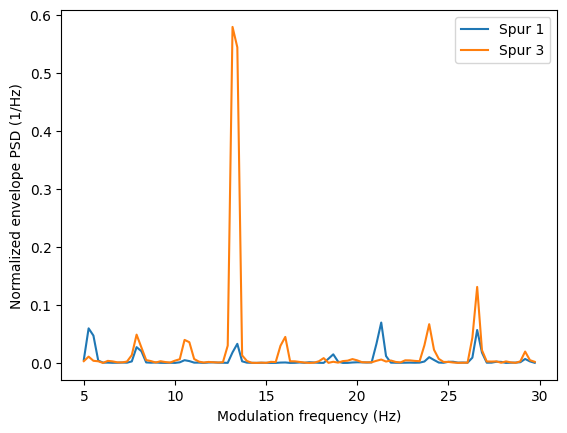

In [19]:
from scipy.signal import butter, sosfiltfilt, hilbert, periodogram

for case in [1, 3]:
    data = np.loadtxt(f"spur {case}_40hz_High_1.txt")

    p = data[:, 2]
    level = np.mean(np.percentile(p, [5, 95]))
    edges = np.where((p[:-1] < level) & (p[1:] >= level))[0] + 1
    fin = fs / np.median(edges[10:] - edges[:-10])

    x = data[:, 0] - np.mean(data[:, 0])
    fc = 48 * fin

    sos = butter(4, [fc-45, fc+45], btype="bandpass", fs=fs, output="sos")
    y = sosfiltfilt(sos, x)

    envelope = np.abs(hilbert(y))
    n = int(0.1 * fs)
    envelope = envelope[n:-n]
    envelope = envelope / np.mean(envelope) - 1

    fe, pe = periodogram(envelope, fs, window="hann")
    band = (fe >= 5) & (fe <= 30)
    plt.plot(fe[band], pe[band], label=f"Spur {case}")

    fm = fin / 3
    near = np.abs(fe - fm) <= 1
    power = np.sum(pe[near]) * (fe[1] - fe[0])
    print(case, "fm:", round(fm, 3), "power:", power)

plt.xlabel("Modulation frequency (Hz)")
plt.ylabel("Normalized envelope PSD (1/Hz)")
plt.legend()
plt.show()


1 Turns: 49 Peak-to-peak: 0.7179306806659131 Correlation: 0.9447737557974574


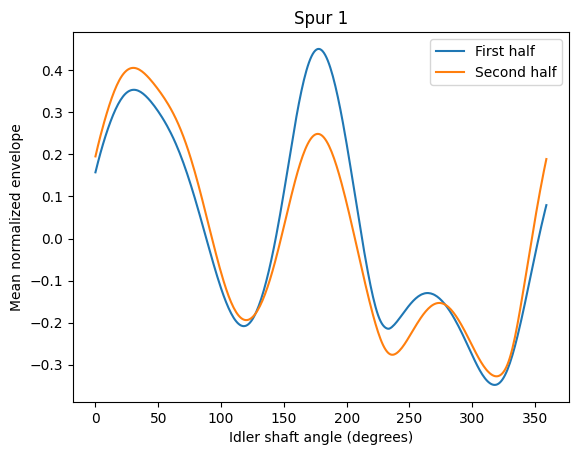

3 Turns: 49 Peak-to-peak: 1.8403187215683223 Correlation: 0.9936683360606533


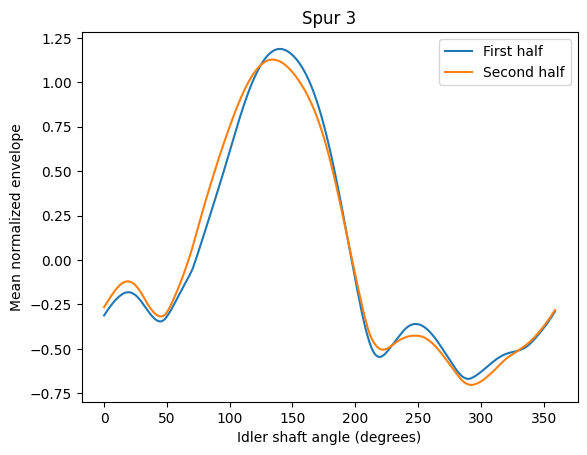

In [20]:

from scipy.signal import butter, sosfiltfilt, hilbert

angle = np.arange(360)

for case in [1, 3]:
    data = np.loadtxt(f"spur {case}_40hz_High_1.txt")

    p = data[:, 2]
    level = np.mean(np.percentile(p, [5, 95]))
    edges = np.where((p[:-1] < level) & (p[1:] >= level))[0] + 1

    fin = fs / np.median(edges[10:] - edges[:-10])
    fc = 48 * fin

    x = data[:, 0] - np.mean(data[:, 0])
    sos = butter(4, [fc-45, fc+45], btype="bandpass", fs=fs, output="sos")

    envelope = np.abs(hilbert(sosfiltfilt(sos, x)))
    envelope = envelope / np.mean(envelope) - 1

    turns = []

    for i in range(0, len(edges)-30, 30):
        ticks = edges[i:i+31]

        if ticks[0] < 0.1*fs or ticks[-1] > len(x)-0.1*fs:
            continue

        samples = np.interp(angle / 12, np.arange(31), ticks)
        turns.append(np.interp(samples, np.arange(len(x)), envelope))

    average = np.mean(turns, axis=0)

    mid = len(turns) // 2

    first = np.mean(turns[:mid], axis=0)
    second = np.mean(turns[mid:], axis=0)

    r = np.corrcoef(first, second)[0, 1]

    print(case, "Turns:", len(turns), "Peak-to-peak:", np.ptp(average), "Correlation:", r)

    plt.figure()
    plt.plot(angle, first, label="First half")
    plt.plot(angle, second, label="Second half")
    plt.title(f"Spur {case}")
    plt.xlabel("Idler shaft angle (degrees)")
    plt.ylabel("Mean normalized envelope")
    plt.legend()
    plt.show()




In [21]:
data = np.loadtxt("spur 1_40hz_High_1.txt")
x = data[:, 0] - np.mean(data[:, 0])
t = np.arange(len(x)) / fs

X = np.abs(np.fft.rfft(x * np.hanning(len(x))))
f = np.fft.rfftfreq(len(x), 1/fs)

band = (f >= 1900) & (f <= 1930)
fc = f[band][np.argmax(X[band])]

print("Carrier:", fc)


Carrier: 1915.8267288566544


In [22]:
sos = butter(4, [fc-3, fc+3], btype="bandpass", fs=fs, output="sos")

y = sosfiltfilt(sos, x)
phase = np.unwrap(np.angle(hilbert(y)))


In [23]:
valid = (t > 0.5) & (t < t[-1]-0.5)
slope = np.polyfit(t[valid], phase[valid], 1)[0]
rpm_est = 60 * slope / (2*np.pi*48)

print("Estimated RPM:", rpm_est)

Estimated RPM: 2394.9192273202975


In [24]:
p = data[:, 2]

level = np.mean(np.percentile(p, [5, 95]))
edges = np.where((p[:-1] < level) & (p[1:] >= level))[0] + 1

theta_ref = np.interp(
    t, edges/fs, 2*np.pi*np.arange(len(edges))/10
)

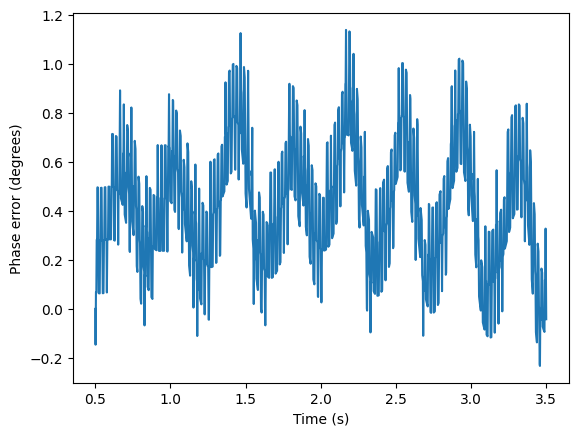

Median absolute error: 0.4188936825464735


In [25]:
i = np.where(valid)[0][0]

theta_est = (phase - phase[i]) / 48
theta_ref = theta_ref - theta_ref[i]

error = np.rad2deg(theta_est - theta_ref)

plt.plot(t[valid], error[valid])
plt.xlabel("Time (s)")
plt.ylabel("Phase error (degrees)")
plt.show()

print("Median absolute error:", np.median(np.abs(error[valid])))

In [26]:
rpm_ref = 60 * np.polyfit(t[valid], theta_ref[valid], 1)[0] / (2*np.pi)

print("Vibration RPM:", rpm_est)
print("Tachometer RPM:", rpm_ref)
print("RPM difference:", rpm_est - rpm_ref)
print("Phase error drift (deg/s):", np.polyfit(t[valid], error[valid], 1)[0])
print("Phase error RMS (deg):", np.sqrt(np.mean(error[valid]**2)))
print("95th absolute error (deg):", np.percentile(np.abs(error[valid]), 95))


Vibration RPM: 2394.9192273202975
Tachometer RPM: 2394.921861536387
RPM difference: -0.002634216089518304
Phase error drift (deg/s): -0.015805296537423814
Phase error RMS (deg): 0.4910986427017665
95th absolute error (deg): 0.8499293586118427


Non-increasing steps: 0


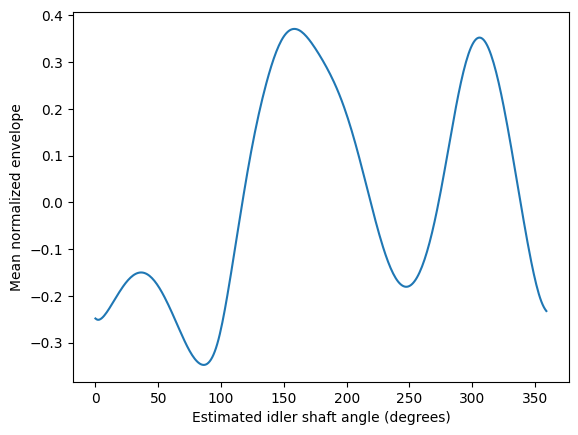

Turns: 39
Peak-to-peak: 0.718306625363009


In [27]:

theta = (phase[valid] - phase[valid][0]) / 144

print("Non-increasing steps:", np.sum(np.diff(theta) <= 0))


sos = butter(4, [fc-45, fc+45], btype="bandpass", fs=fs, output="sos")
envelope = np.abs(hilbert(sosfiltfilt(sos, x)))

envelope = envelope / np.mean(envelope[valid]) - 1
envelope = envelope[valid]

angle = np.arange(360)
turns = []

for k in range(int(theta[-1] / (2*np.pi))):
    points = 2*np.pi * (k + angle/360)
    turns.append(np.interp(points, theta, envelope))

average = np.mean(turns, axis=0)

plt.plot(angle, average)
plt.xlabel("Estimated idler shaft angle (degrees)")
plt.ylabel("Mean normalized envelope")
plt.show()

print("Turns:", len(turns))
print("Peak-to-peak:", np.ptp(average))


In [28]:
p = data[:, 2]

level = np.mean(np.percentile(p, [5, 95]))
edges = np.where((p[:-1] < level) & (p[1:] >= level))[0] + 1

theta_tach = np.interp(
    t[valid],
    edges / fs,
    2*np.pi*np.arange(len(edges)) / 30
)

theta_tach -= theta_tach[0]

In [29]:
n_turns = int(min(theta[-1], theta_tach[-1]) / (2*np.pi))
print("Common turns:", n_turns)

Common turns: 39


In [30]:
profiles = []

for shaft_angle in [theta_tach, theta]:
    turns = []

    for k in range(n_turns):
        positions = 2*np.pi * (k + angle/360)
        turns.append(np.interp(positions, shaft_angle, envelope))

    profiles.append(np.mean(turns, axis=0))

reference, virtual = profiles

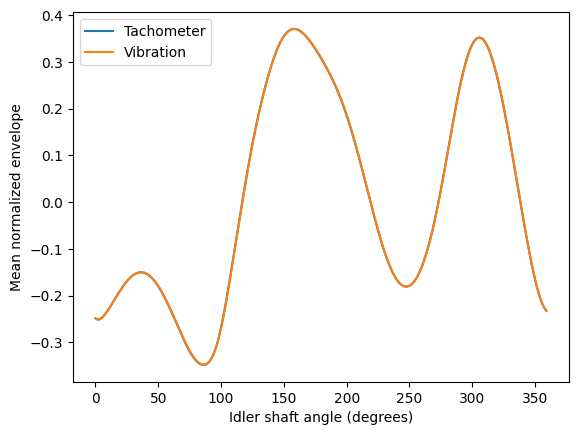

Profile correlation: 0.9999838583664907
Tachometer peak-to-peak: 0.7187805324999801
Vibration peak-to-peak: 0.718306625363009


In [31]:
plt.plot(angle, reference, label="Tachometer")
plt.plot(angle, virtual, label="Vibration")

plt.xlabel("Idler shaft angle (degrees)")
plt.ylabel("Mean normalized envelope")
plt.legend()
plt.show()

print("Profile correlation:", np.corrcoef(reference, virtual)[0, 1])
print("Tachometer peak-to-peak:", np.ptp(reference))
print("Vibration peak-to-peak:", np.ptp(virtual))

In [32]:
time = t[valid] - t[valid][0]
theta_const = 2*np.pi * (rpm_est/60) * time / 3

for name, shaft_angle in [("Hilbert", theta), ("Constant RPM", theta_const)]:
    error = np.rad2deg(shaft_angle - theta_tach)

    rms = np.sqrt(np.mean(error**2))
    p95 = np.percentile(np.abs(error), 95)

    print(name, "RMS:", rms, "95%:", p95)


Hilbert RMS: 0.1636995475672755 95%: 0.283309786203839
Constant RPM RMS: 0.2422273678604955 95%: 0.3739611852740892


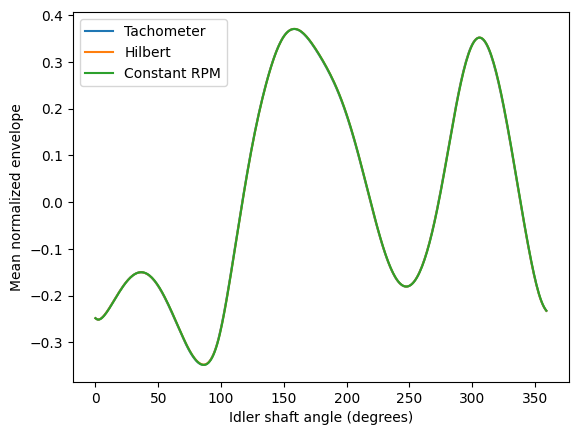

Hilbert Correlation: 0.9999838583664907 Peak-to-peak: 0.718306625363009
Constant RPM Correlation: 0.9999647356688217 Peak-to-peak: 0.7188536557497305


In [33]:

n_turns = int(min(theta_tach[-1], theta[-1], theta_const[-1]) / (2*np.pi))

profiles = []

for shaft_angle in [theta_tach, theta, theta_const]:
    turns = []

    for k in range(n_turns):
        positions = 2*np.pi * (k + angle/360)
        turns.append(np.interp(positions, shaft_angle, envelope))

    profiles.append(np.mean(turns, axis=0))

for name, profile in zip(["Tachometer", "Hilbert", "Constant RPM"], profiles):
    plt.plot(angle, profile, label=name)

plt.xlabel("Idler shaft angle (degrees)")
plt.ylabel("Mean normalized envelope")
plt.legend()
plt.show()

for name, profile in zip(["Hilbert", "Constant RPM"], profiles[1:]):
    r = np.corrcoef(profiles[0], profile)[0, 1]
    print(name, "Correlation:", r, "Peak-to-peak:", np.ptp(profile))


In [34]:
data = np.loadtxt("spur 3_40hz_High_1.txt")

x = data[:, 0] - np.mean(data[:, 0])
t = np.arange(len(x)) / fs

f = np.fft.rfftfreq(len(x), 1/fs)
A = np.abs(np.fft.rfft(x * np.hanning(len(x))))

band = np.abs(f - 1915.83) <= 7
fc = f[band][np.argmax(A[band])]

sos = butter(4, [fc-3, fc+3], btype="bandpass", fs=fs, output="sos")
phase = np.unwrap(np.angle(hilbert(sosfiltfilt(sos, x))))

valid = (t > 0.5) & (t < t[-1]-0.5)
time = t[valid] - t[valid][0]

theta_h = (phase[valid] - phase[valid][0]) / 144

rpm_h = 60 * 3 * np.polyfit(time, theta_h, 1)[0] / (2*np.pi)
theta_c = 2*np.pi * (rpm_h/60) * time / 3

print("Carrier candidate:", fc)
print("Estimated RPM:", rpm_h)


Carrier candidate: 1912.5765986889478
Estimated RPM: 2390.555920634852


In [35]:
p = data[:, 2]

low, high = np.percentile(p, [5, 95])
level = (low + high) / 2

edges = np.where((p[:-1] < level) & (p[1:] >= level))[0] + 1

theta_t = np.interp(
    t[valid], edges/fs, 2*np.pi*np.arange(len(edges))/30
)

theta_t -= theta_t[0]


Reference RPM: 2390.5560907432714
Non-increasing steps: 0
Hilbert RMS: 0.13082412605244148 95%: 0.24640144340029133
Constant RPM RMS: 0.13429351677655826 95%: 0.23176920148528257


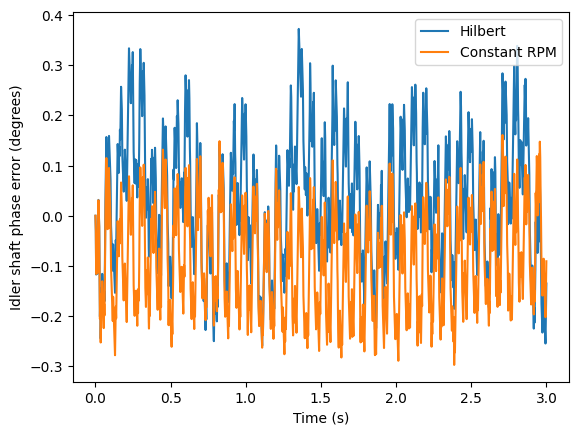

In [36]:
rpm_t = 60 * 3 * np.polyfit(time, theta_t, 1)[0] / (2*np.pi)

print("Reference RPM:", rpm_t)
print("Non-increasing steps:", np.sum(np.diff(theta_h) <= 0))

for name, theta in [("Hilbert", theta_h), ("Constant RPM", theta_c)]:
    error = np.rad2deg(theta - theta_t)

    rms = np.sqrt(np.mean(error**2))
    p95 = np.percentile(np.abs(error), 95)

    print(name, "RMS:", rms, "95%:", p95)

    plt.plot(time, error, label=name)

plt.xlabel("Time (s)")
plt.ylabel("Idler shaft phase error (degrees)")
plt.legend()
plt.show()


In [37]:
sos = butter(4, [fc-45, fc+45], btype="bandpass", fs=fs, output="sos")

e = np.abs(hilbert(sosfiltfilt(sos, x)))[valid]
e = e / np.mean(e) - 1

In [38]:
angle = np.arange(360)
shaft_angles = [theta_t, theta_h, theta_c]

n_turns = int(min(a[-1] for a in shaft_angles) / (2*np.pi))

profiles = []

for shaft_angle in shaft_angles:
    turns = []

    for k in range(n_turns):
        positions = 2*np.pi * (k + angle/360)
        turns.append(np.interp(positions, shaft_angle, e))

    profiles.append(np.mean(turns, axis=0))


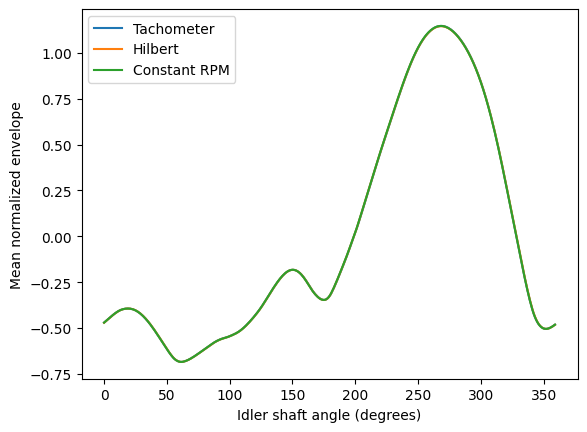

In [39]:
names = ["Tachometer", "Hilbert", "Constant RPM"]

for name, profile in zip(names, profiles):
    plt.plot(angle, profile, label=name)

plt.xlabel("Idler shaft angle (degrees)")
plt.ylabel("Mean normalized envelope")
plt.legend()
plt.show()

In [40]:
reference = profiles[0]

print("Common turns:", n_turns)

for name, profile in zip(names[1:], profiles[1:]):
    correlation = np.corrcoef(reference, profile)[0, 1]
    rmse = np.sqrt(np.mean((profile - reference)**2))

    print(name)
    print("Correlation:", correlation)
    print("Profile RMSE:", rmse)
    print("Peak-to-peak:", np.ptp(profile))
    print("Reference peak-to-peak:", np.ptp(reference))

Common turns: 39
Hilbert
Correlation: 0.999997115108216
Profile RMSE: 0.0014840201841209487
Peak-to-peak: 1.8299707497563862
Reference peak-to-peak: 1.83165852772848
Constant RPM
Correlation: 0.9999954274740595
Profile RMSE: 0.0018493853555352866
Peak-to-peak: 1.8314872306561276
Reference peak-to-peak: 1.83165852772848


In [41]:
speed = 30
case = 1

data = np.loadtxt(f"spur {case}_{speed}hz_High_1.txt")

x = data[:, 0] - np.mean(data[:, 0])
t = np.arange(len(x)) / fs

f = np.fft.rfftfreq(len(x), 1/fs)
spectrum = np.abs(np.fft.rfft(x * np.hanning(len(x))))

expected = 48 * speed
band = np.abs(f - expected) <= 8
fc = f[band][np.argmax(spectrum[band])]

print("Expected carrier:", expected)
print("Detected carrier:", fc)


Expected carrier: 1440
Detected carrier: 1435.5628776508972


In [42]:
sos = butter(4, [fc-3, fc+3], btype="bandpass", fs=fs, output="sos")

phase = np.unwrap(np.angle(hilbert(sosfiltfilt(sos, x))))

valid = (t > 0.5) & (t < t[-1]-0.5)
time = t[valid] - t[valid][0]

theta_h = (phase[valid] - phase[valid][0]) / 144

rpm_h = 60 * 3 * np.polyfit(time, theta_h, 1)[0] / (2*np.pi)

theta_c = 2*np.pi * (rpm_h/60) * time / 3


In [43]:
p = data[:, 2]

level = np.mean(np.percentile(p, [5, 95]))
edges = np.where((p[:-1] < level) & (p[1:] >= level))[0] + 1

theta_t = np.interp(
    t[valid], edges/fs, 2*np.pi*np.arange(len(edges))/30
)

theta_t -= theta_t[0]

rpm_t = 60 * 3 * np.polyfit(time, theta_t, 1)[0] / (2*np.pi)

print("Vibration RPM:", rpm_h)
print("Tachometer RPM:", rpm_t)
print("Observed order:", fc / (rpm_t/60))


Vibration RPM: 1794.3325991836953
Tachometer RPM: 1794.3273812183486
Observed order: 48.003376396434966


In [44]:
for name, theta in [("Hilbert", theta_h), ("Constant RPM", theta_c)]:
    error = np.rad2deg(theta - theta_t)

    rms = np.sqrt(np.mean(error**2))
    p95 = np.percentile(np.abs(error), 95)

    print(name, "RMS:", rms, "95%:", p95)


Hilbert RMS: 0.09002309506559406 95%: 0.16889425027339283
Constant RPM RMS: 0.08280665264161717 95%: 0.1628487072758264


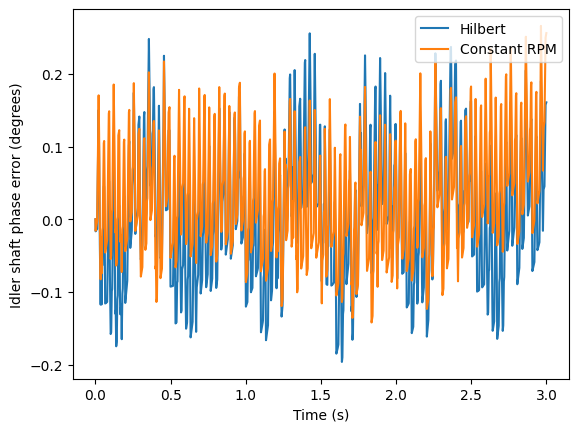

In [45]:
plt.plot(time, np.rad2deg(theta_h-theta_t), label="Hilbert")
plt.plot(time, np.rad2deg(theta_c-theta_t), label="Constant RPM")

plt.xlabel("Time (s)")
plt.ylabel("Idler shaft phase error (degrees)")
plt.legend(loc="upper right")
plt.show()


In [46]:
speed = 30
case = 3

data = np.loadtxt(f"spur {case}_{speed}hz_High_1.txt")

x = data[:, 0] - np.mean(data[:, 0])
t = np.arange(len(x)) / fs

f = np.fft.rfftfreq(len(x), 1/fs)
spectrum = np.abs(np.fft.rfft(x * np.hanning(len(x))))

expected = 48 * speed
band = np.abs(f - expected) <= 8
fc = f[band][np.argmax(spectrum[band])]

print("Expected carrier:", expected)
print("Detected carrier:", fc)

Expected carrier: 1440
Detected carrier: 1436.0575141005643


In [47]:
sos = butter(4, [fc-3, fc+3], btype="bandpass", fs=fs, output="sos")

phase = np.unwrap(np.angle(hilbert(sosfiltfilt(sos, x))))

valid = (t > 0.5) & (t < t[-1]-0.5)
time = t[valid] - t[valid][0]

theta_h = (phase[valid] - phase[valid][0]) / 144

rpm_h = 60 * 3 * np.polyfit(time, theta_h, 1)[0] / (2*np.pi)

theta_c = 2*np.pi * (rpm_h/60) * time / 3

In [48]:
p = data[:, 2]

level = np.mean(np.percentile(p, [5, 95]))
edges = np.where((p[:-1] < level) & (p[1:] >= level))[0] + 1

theta_t = np.interp(
    t[valid], edges/fs, 2*np.pi*np.arange(len(edges))/30
)

theta_t -= theta_t[0]

rpm_t = 60 * 3 * np.polyfit(time, theta_t, 1)[0] / (2*np.pi)

print("Vibration RPM:", rpm_h)
print("Tachometer RPM:", rpm_t)
print("Observed order:", fc / (rpm_t/60))

Vibration RPM: 1795.1523492978513
Tachometer RPM: 1795.181960849115
Observed order: 47.997056969800894


In [49]:
for name, theta in [("Hilbert", theta_h), ("Constant RPM", theta_c)]:
    error = np.rad2deg(theta - theta_t)

    rms = np.sqrt(np.mean(error**2))
    p95 = np.percentile(np.abs(error), 95)

    print(name, "RMS:", rms, "95%:", p95)


Hilbert RMS: 0.3565579966517207 95%: 0.6551798608577393
Constant RPM RMS: 0.26646582266562063 95%: 0.4727988654550769


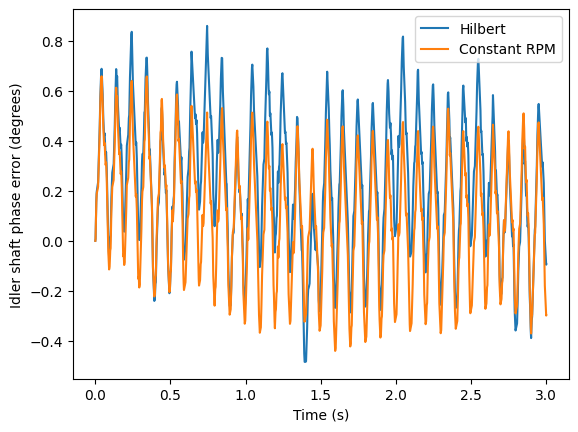

In [50]:
plt.plot(time, np.rad2deg(theta_h-theta_t), label="Hilbert")
plt.plot(time, np.rad2deg(theta_c-theta_t), label="Constant RPM")

plt.xlabel("Time (s)")
plt.ylabel("Idler shaft phase error (degrees)")
plt.legend(loc="upper right")
plt.show()


In [51]:
order = fc / (rpm_t / 60)

print("Selected frequency:", fc)
print("Observed order:", order)
print("Expected carrier:", 48 * rpm_t / 60)

Selected frequency: 1436.0575141005643
Observed order: 47.997056969800894
Expected carrier: 1436.145568679292


Hilbert RMS: 0.3565579966517207 95%: 0.6551798608577393
Constant RPM RMS: 0.26646582266562063 95%: 0.4727988654550769


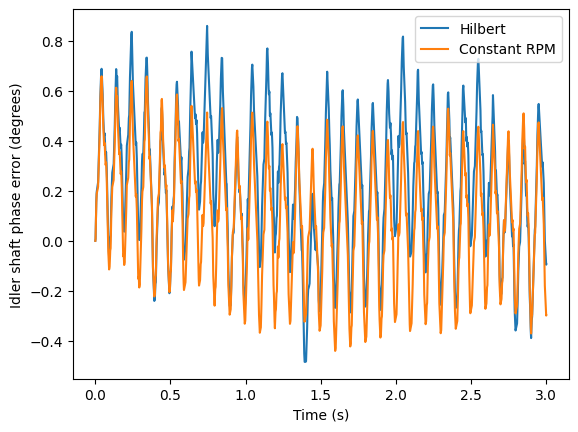

In [52]:
for name, theta in [("Hilbert", theta_h), ("Constant RPM", theta_c)]:
    error = np.rad2deg(theta - theta_t)

    rms = np.sqrt(np.mean(error**2))
    p95 = np.percentile(np.abs(error), 95)

    print(name, "RMS:", rms, "95%:", p95)
    plt.plot(time, error, label=name)

plt.xlabel("Time (s)")
plt.ylabel("Idler shaft phase error (degrees)")
plt.legend(loc="upper right")
plt.show()


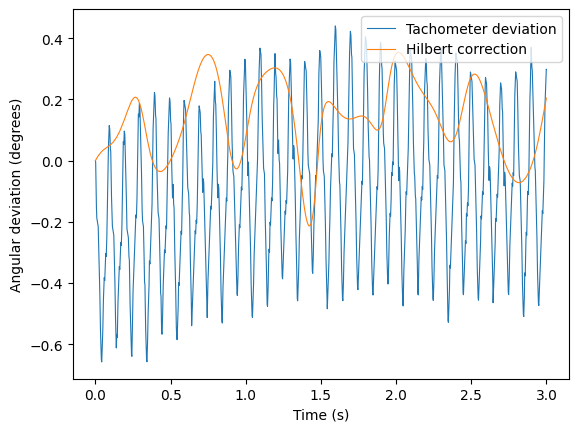

Correlation: 0.047755012879371804


In [53]:
r = np.rad2deg(theta_t - theta_c)
d = np.rad2deg(theta_h - theta_c)

plt.plot(time, r, label="Tachometer deviation", linewidth=0.8)
plt.plot(time, d, label="Hilbert correction", linewidth=0.8)

plt.xlabel("Time (s)")
plt.ylabel("Angular deviation (degrees)")
plt.legend(loc="upper right")
plt.show()

print("Correlation:", np.corrcoef(r, d)[0, 1])

In [54]:
penalty = np.mean(d**2)
gain = 2 * np.mean(d*r)

print("Correction energy:", penalty)
print("Alignment benefit:", gain)
print("MSE difference:", penalty - gain)

Correction energy: 0.03322961967248792
Alignment benefit: -0.022899950654934605
MSE difference: 0.05612957032742252


Tachometer Peak frequency: 10.000600536032161
Hilbert Peak frequency: 6.000360321619297


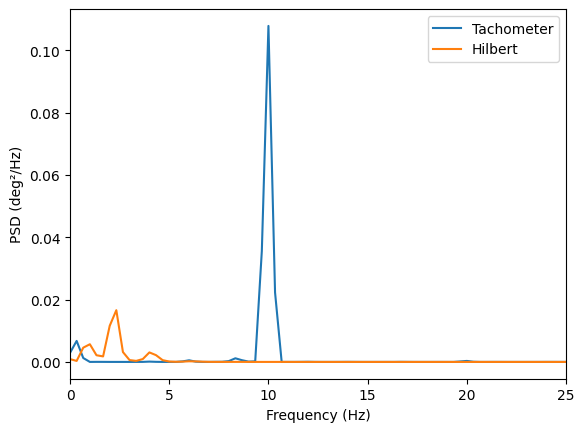

Correlation: 0.047755012879371804


In [55]:
for name, signal in [("Tachometer", r), ("Hilbert", d)]:
    freq, psd = periodogram(signal - np.mean(signal), fs, window="hann")

    plt.plot(freq, psd, label=name)

    band = (freq >= 5) & (freq <= 20)
    peak = freq[band][np.argmax(psd[band])]

    print(name, "Peak frequency:", peak)

plt.xlim(0, 25)
plt.xlabel("Frequency (Hz)")
plt.ylabel("PSD (deg²/Hz)")
plt.legend()
plt.show()

print("Correlation:", np.corrcoef(r, d)[0, 1])


In [56]:
widths = [3,12,20]

for width in widths:

    sos = butter(
        4,
        [fc-width, fc+width],
        btype="bandpass",
        fs=fs,
        output="sos"
    )

    phase = np.unwrap(
        np.angle(
            hilbert(
                sosfiltfilt(sos,x)
            )
        )
    )

    theta_h = (phase[valid]-phase[valid][0])/144

    error = np.rad2deg(theta_h-theta_t)

    rms = np.sqrt(np.mean(error**2))
    p95 = np.percentile(np.abs(error),95)

    print(width,rms,p95)

3 0.3565579966517207 0.6551798608577393
12 6.2538468546390655 10.440343966173694
20 9.398114150079929 18.942574149777187


In [57]:
from pathlib import Path

results = []
angle = np.arange(360)

for speed in [30, 40, 50]:
    for case in [1, 3]:
        filename = Path(f"spur {case}_{speed}hz_High_1.txt")

        if not filename.exists():
            print("Missing recording:", filename.name)
            continue

        data = np.loadtxt(filename)
        x = data[:, 0] - np.mean(data[:, 0])
        t = np.arange(len(x)) / fs

        f = np.fft.rfftfreq(len(x), 1/fs)
        spectrum = np.abs(np.fft.rfft(x * np.hanning(len(x))))
        band = np.abs(f - 48*speed) <= 8
        fc = f[band][np.argmax(spectrum[band])]

        sos = butter(4, [fc-3, fc+3], btype="bandpass", fs=fs, output="sos")
        phase = np.unwrap(np.angle(hilbert(sosfiltfilt(sos, x))))

        valid = (t > 0.5) & (t < t[-1]-0.5)
        time = t[valid] - t[valid][0]
        theta_h = (phase[valid] - phase[valid][0]) / 144
        rpm_h = 60*3*np.polyfit(time, theta_h, 1)[0] / (2*np.pi)
        theta_c = 2*np.pi*(rpm_h/60)*time/3

        p = data[:, 2]
        level = np.mean(np.percentile(p, [5, 95]))
        edges = np.where((p[:-1] < level) & (p[1:] >= level))[0] + 1
        theta_t = np.interp(t[valid], edges/fs, 2*np.pi*np.arange(len(edges))/30)
        theta_t -= theta_t[0]
        rpm_t = 60*3*np.polyfit(time, theta_t, 1)[0] / (2*np.pi)

        if np.any(np.diff(theta_h) <= 0):
            print("Non-monotonic phase:", filename.name)
            continue

        sos = butter(4, [fc-45, fc+45], btype="bandpass", fs=fs, output="sos")
        e = np.abs(hilbert(sosfiltfilt(sos, x)))[valid]
        e = e/np.mean(e) - 1

        shaft_angles = [theta_t, theta_h, theta_c]
        n_turns = int(min(a[-1] for a in shaft_angles) / (2*np.pi))
        if n_turns < 2:
            print("Insufficient turns:", filename.name)
            continue

        profiles = []
        for shaft_angle in shaft_angles:
            turns = []
            for k in range(n_turns):
                positions = 2*np.pi*(k + angle/360)
                turns.append(np.interp(positions, shaft_angle, e))
            profiles.append(np.mean(turns, axis=0))

        reference, hilbert_profile, constant_profile = profiles
        err_h = np.rad2deg(theta_h - theta_t)
        err_c = np.rad2deg(theta_c - theta_t)

        results.append({
            "speed": speed, "case": case, "turns": n_turns,
            "rpm_t": rpm_t, "rpm_h": rpm_h, "fc": fc,
            "order": fc/(rpm_t/60),
            "rms_h": np.sqrt(np.mean(err_h**2)),
            "rms_c": np.sqrt(np.mean(err_c**2)),
            "p95_h": np.percentile(np.abs(err_h), 95),
            "p95_c": np.percentile(np.abs(err_c), 95),
            "corr_h": np.corrcoef(reference, hilbert_profile)[0, 1],
            "corr_c": np.corrcoef(reference, constant_profile)[0, 1],
            "rmse_h": np.sqrt(np.mean((hilbert_profile-reference)**2)),
            "rmse_c": np.sqrt(np.mean((constant_profile-reference)**2)),
            "ptp_t": np.ptp(reference),
            "ptp_h": np.ptp(hilbert_profile),
            "ptp_c": np.ptp(constant_profile),
            "profiles": profiles
        })

        print(f"{speed} Hz | Spur {case} | {n_turns} turns | order {fc/(rpm_t/60):.4f}")


30 Hz | Spur 1 | 29 turns | order 48.0034
30 Hz | Spur 3 | 29 turns | order 47.9971
40 Hz | Spur 1 | 39 turns | order 47.9972
40 Hz | Spur 3 | 39 turns | order 48.3359
Missing recording: spur 1_50hz_High_1.txt
Missing recording: spur 3_50hz_High_1.txt


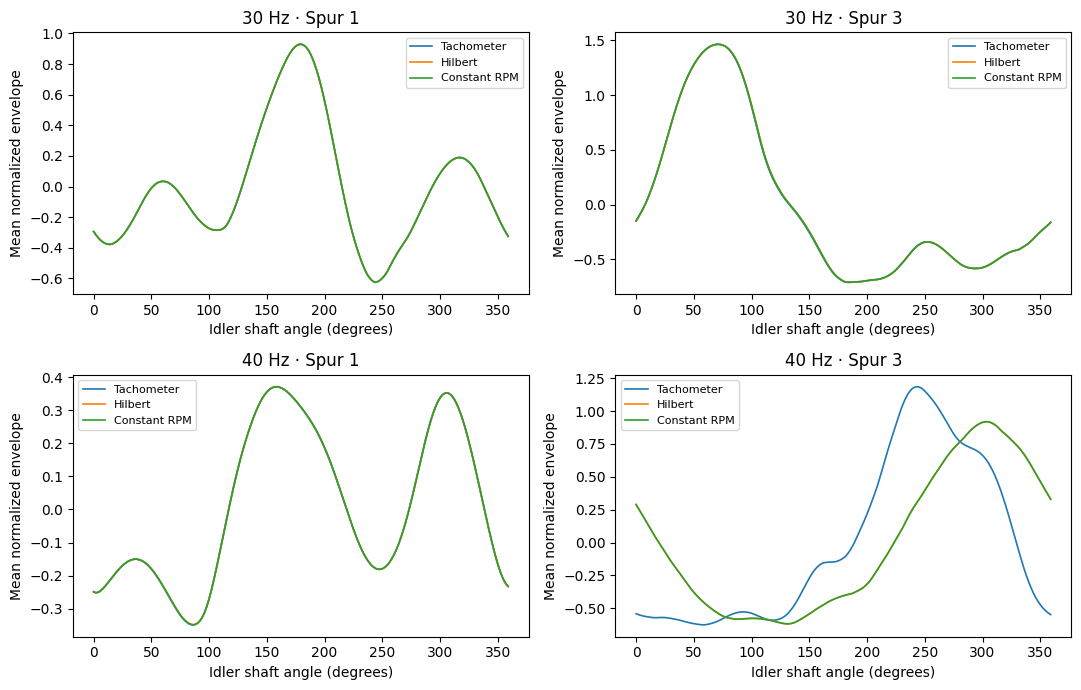

In [58]:
if results:
    speeds = sorted(set(row["speed"] for row in results))
    fig, axes = plt.subplots(len(speeds), 2, figsize=(11, 3.5*len(speeds)), squeeze=False)

    for row in results:
        ax = axes[speeds.index(row["speed"]), 0 if row["case"] == 1 else 1]
        for name, profile in zip(["Tachometer", "Hilbert", "Constant RPM"], row["profiles"]):
            ax.plot(angle, profile, label=name, linewidth=1.2)
        ax.set_title(f'{row["speed"]} Hz · Spur {row["case"]}')
        ax.set_xlabel("Idler shaft angle (degrees)")
        ax.set_ylabel("Mean normalized envelope")
        ax.legend(fontsize=8)

    for ax in axes.flat:
        if not ax.lines:
            ax.axis("off")

    plt.tight_layout()
    plt.show()


In [59]:
print("FINAL VALIDATION — High load, first recording")
print("Shaft angle: idler degrees | Reference: measured tachometer")
print()

if results:
    print("Speed  Spur   RPM diff    48X order   RMS H / C (deg)   TSA corr H / C      Profile RMSE H / C")
    for row in results:
        print(f'{row["speed"]:>3} Hz   {row["case"]}   {row["rpm_h"]-row["rpm_t"]:+9.4f}   '
              f'{row["order"]:9.4f}   {row["rms_h"]:6.4f} / {row["rms_c"]:6.4f}   '
              f'{row["corr_h"]:.7f} / {row["corr_c"]:.7f}   '
              f'{row["rmse_h"]:.5f} / {row["rmse_c"]:.5f}')

    print("\nAdditional checks")
    for row in results:
        winner = "Hilbert" if row["rms_h"] < row["rms_c"] else "Constant RPM"
        print(f'{row["speed"]} Hz, Spur {row["case"]}: {row["turns"]} common turns; '
              f'better instantaneous RMS: {winner}; '
              f'95% error H/C: {row["p95_h"]:.4f}° / {row["p95_c"]:.4f}°; '
              f'peak-to-peak T/H/C: {row["ptp_t"]:.4f} / {row["ptp_h"]:.4f} / {row["ptp_c"]:.4f}')
else:
    print("No raw recordings found. Place the labeled .txt files beside this notebook and run all cells.")

print("\nPreviously observed at nominal 40 Hz")
print("Idler 1X normalized envelope power: healthy 0.014565; eccentric 0.308247 (21.16x).")
print("These are matched-recording observations, not fault classification accuracy.")
print("\nPhase-tracking limitation — eccentric gearbox, nominal 30 Hz")
print("Narrowband Hilbert RMS: 0.3566°; constant-RPM RMS: 0.2665°.")
print("Increasing the phase-filter half-width from 3 to 12 and 20 Hz raised RMS to 6.2538° and 9.3981°.")
print("\nConclusion")
print("Vibration-based angular references reproduced tachometer-synchronous envelope TSA under tested steady speeds.")
print("Very high TSA correlation does not demonstrate superiority over the constant-RPM baseline.")
print("The tests do not validate speed ramps, independent repeats, real-time use, or general fault detection.")


FINAL VALIDATION — High load, first recording
Shaft angle: idler degrees | Reference: measured tachometer

Speed  Spur   RPM diff    48X order   RMS H / C (deg)   TSA corr H / C      Profile RMSE H / C
 30 Hz   1     +0.0052     48.0034   0.0900 / 0.0828   0.9999965 / 0.9999953   0.00124 / 0.00139
 30 Hz   3     -0.0296     47.9971   0.3566 / 0.2665   0.9999668 / 0.9999876   0.00621 / 0.00424
 40 Hz   1     -0.0026     47.9972   0.1637 / 0.2422   0.9999839 / 0.9999647   0.00132 / 0.00194
 40 Hz   3    +16.5945     48.3359   57.3750 / 57.4029   0.6202607 / 0.6200640   0.50604 / 0.50616

Additional checks
30 Hz, Spur 1: 29 common turns; better instantaneous RMS: Constant RPM; 95% error H/C: 0.1689° / 0.1628°; peak-to-peak T/H/C: 1.5541 / 1.5542 / 1.5540
30 Hz, Spur 3: 29 common turns; better instantaneous RMS: Constant RPM; 95% error H/C: 0.6552° / 0.4728°; peak-to-peak T/H/C: 2.1754 / 2.1736 / 2.1745
40 Hz, Spur 1: 39 common turns; better instantaneous RMS: Hilbert; 95% error H/C: 0.283